# TASK : 1

In [32]:
!pip install -q transformers torch

In [33]:
from transformers import pipeline

clf = pipeline("sentiment-analysis",
               model="distilbert/distilbert-base-uncased-finetuned-sst-2-english")

texts = ["I love this product", "This is terrible",
         "The movie was okay", "Amazing experience", "I hate this"]

for text, result in zip(texts, clf(texts)):
    print(text, "->", result)

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

I love this product -> {'label': 'POSITIVE', 'score': 0.9998788833618164}
This is terrible -> {'label': 'NEGATIVE', 'score': 0.9996459484100342}
The movie was okay -> {'label': 'POSITIVE', 'score': 0.9997923970222473}
Amazing experience -> {'label': 'POSITIVE', 'score': 0.9998812675476074}
I hate this -> {'label': 'NEGATIVE', 'score': 0.9996224641799927}


In [34]:
from IPython.display import display, Markdown

display(Markdown("""
| Year | Development |
|---|---|
| 2014 | Seq2Seq models for sequence learning |
| 2015 | Attention mechanisms improved sequence tasks |
| 2017 | Transformer introduced |
| 2018 | BERT and GPT introduced |
| 2019 | GPT-2 and Transformer improvements |
| 2020 | GPT-3 demonstrated large-scale language learning |

**Transformer:** Uses self-attention to process relationships between tokens.
**RNN/LSTM:** Processes sequences step by step, making long-range dependencies harder to learn.
"""))


| Year | Development |
|---|---|
| 2014 | Seq2Seq models for sequence learning |
| 2015 | Attention mechanisms improved sequence tasks |
| 2017 | Transformer introduced |
| 2018 | BERT and GPT introduced |
| 2019 | GPT-2 and Transformer improvements |
| 2020 | GPT-3 demonstrated large-scale language learning |

**Transformer:** Uses self-attention to process relationships between tokens.
**RNN/LSTM:** Processes sequences step by step, making long-range dependencies harder to learn.


display(Markdown("""
### Impact
- Translation and text summarization
- Chatbots and virtual assistants
- Code generation and completion
- Image generation and protein research

### Disadvantages
- High computational and memory costs
- Limited context window
- Hallucinations and incorrect answers
- Bias and opaque decision-making
"""))

In [35]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained(
    "distilbert/distilbert-base-uncased-finetuned-sst-2-english"
)

text = "Transformers are surprisingly easy to understand."
tokens = tokenizer.tokenize(text)
encoded = tokenizer(text)

print("Tokens:", tokens)
print("Input IDs:", encoded["input_ids"])
print("Attention Mask:", encoded["attention_mask"])
print("Rare word tokens:", tokenizer.tokenize("antidisestablishmentarianism"))
print("[CLS] and [SEP]: Special tokens marking the start and end of a sequence.")
print("Subwords help represent unfamiliar and rare words.")

Tokens: ['transformers', 'are', 'surprisingly', 'easy', 'to', 'understand', '.']
Input IDs: [101, 19081, 2024, 10889, 3733, 2000, 3305, 1012, 102]
Attention Mask: [1, 1, 1, 1, 1, 1, 1, 1, 1]
Rare word tokens: ['anti', '##dis', '##est', '##ab', '##lish', '##ment', '##arian', '##ism']
[CLS] and [SEP]: Special tokens marking the start and end of a sequence.
Subwords help represent unfamiliar and rare words.


In [36]:
texts = ["I love AI.", "Transformers are powerful models for natural language processing."]

batch = tokenizer(texts, padding=True, return_tensors="pt")

print("Input IDs:\n", batch["input_ids"])
print("Attention Mask:\n", batch["attention_mask"])
print("1 = real token, 0 = padding")

Input IDs:
 tensor([[  101,  1045,  2293,  9932,  1012,   102,     0,     0,     0,     0,
             0],
        [  101, 19081,  2024,  3928,  4275,  2005,  3019,  2653,  6364,  1012,
           102]])
Attention Mask:
 tensor([[1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0],
        [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]])
1 = real token, 0 = padding


In [37]:
from transformers import AutoModelForSequenceClassification

model = AutoModelForSequenceClassification.from_pretrained(
    "distilbert/distilbert-base-uncased-finetuned-sst-2-english"
)

config = model.config
print("Layers:", config.n_layers)
print("Attention Heads:", config.n_heads)
print("Hidden Size:", config.dim)
print("Vocabulary Size:", config.vocab_size)
print("Maximum Position Embeddings:", config.max_position_embeddings)

print("\nFirst 15 parameter names:")
for name, param in list(model.named_parameters())[:15]:
    print(name, param.shape)

print("\nTotal Parameters:", sum(p.numel() for p in model.parameters()))

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Layers: 6
Attention Heads: 12
Hidden Size: 768
Vocabulary Size: 30522
Maximum Position Embeddings: 512

First 15 parameter names:
distilbert.embeddings.word_embeddings.weight torch.Size([30522, 768])
distilbert.embeddings.position_embeddings.weight torch.Size([512, 768])
distilbert.embeddings.LayerNorm.weight torch.Size([768])
distilbert.embeddings.LayerNorm.bias torch.Size([768])
distilbert.transformer.layer.0.attention.q_lin.weight torch.Size([768, 768])
distilbert.transformer.layer.0.attention.q_lin.bias torch.Size([768])
distilbert.transformer.layer.0.attention.k_lin.weight torch.Size([768, 768])
distilbert.transformer.layer.0.attention.k_lin.bias torch.Size([768])
distilbert.transformer.layer.0.attention.v_lin.weight torch.Size([768, 768])
distilbert.transformer.layer.0.attention.v_lin.bias torch.Size([768])
distilbert.transformer.layer.0.attention.out_lin.weight torch.Size([768, 768])
distilbert.transformer.layer.0.attention.out_lin.bias torch.Size([768])
distilbert.transformer.l

# TASK : 2

In [38]:
from IPython.display import display, Markdown

display(Markdown("""
### Self-Attention
- **Query (Q):** What information am I looking for?
- **Key (K):** What information does each token contain?
- **Value (V):** What information does each token provide?
- Attention scores = Q × Kᵀ / √dₖ
- Softmax converts scores into attention weights.
- Output = Attention weights × V.
- All tokens are processed in parallel, unlike RNNs.
"""))


### Self-Attention
- **Query (Q):** What information am I looking for?
- **Key (K):** What information does each token contain?
- **Value (V):** What information does each token provide?
- Attention scores = Q × Kᵀ / √dₖ
- Softmax converts scores into attention weights.
- Output = Attention weights × V.
- All tokens are processed in parallel, unlike RNNs.


Attention weights:
 [[0.80793906 0.11522515 0.03211394 0.04472186]
 [0.67983167 0.18132728 0.05839551 0.08044555]
 [0.67871303 0.17470119 0.06288215 0.08370364]
 [0.6808096  0.18195447 0.05732315 0.07991279]]
Row sums: [1. 1. 1. 1.]


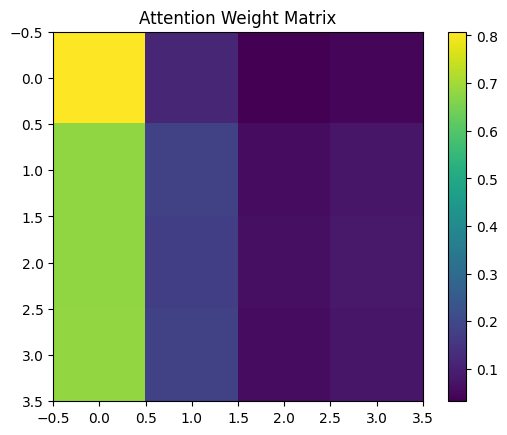

In [39]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
X = np.random.rand(4, 8)
WQ, WK, WV = [np.random.rand(8, 8) for _ in range(3)]

Q, K, V = X @ WQ, X @ WK, X @ WV

def softmax(x):
    x = x - x.max(axis=-1, keepdims=True)
    e = np.exp(x)
    return e / e.sum(axis=-1, keepdims=True)

def attention(Q, K, V):
    scores = Q @ K.T / np.sqrt(Q.shape[-1])
    weights = softmax(scores)
    return weights @ V, weights

output, weights = attention(Q, K, V)

print("Attention weights:\n", weights)
print("Row sums:", weights.sum(axis=1))
plt.imshow(weights, cmap="viridis")
plt.colorbar()
plt.title("Attention Weight Matrix")
plt.show()

In [40]:
np.random.seed(42)

for d in [4, 256]:
    Q, K = np.random.randn(100, d), np.random.randn(100, d)
    scores = Q @ K.T

    for scale in [1, np.sqrt(d)]:
        p = softmax(scores / scale)
        entropy = -(p * np.log(p + 1e-12)).sum(axis=1).mean()
        print(f"d={d}, scale={scale:.1f}, "
              f"max probability={p.max(axis=1).mean():.4f}, "
              f"entropy={entropy:.4f}")

d=4, scale=1.0, max probability=0.2127, entropy=3.2920
d=4, scale=2.0, max probability=0.0702, entropy=4.1797
d=256, scale=1.0, max probability=0.8757, entropy=0.2944
d=256, scale=16.0, max probability=0.0812, entropy=4.1277


In [41]:
np.random.seed(42)

encoder = np.random.rand(5, 8)
decoder = np.random.rand(8)

# Luong dot-product attention
scores = encoder @ decoder
weights = softmax(scores)
context = weights @ encoder

print("Luong attention weights:", weights)
print("Context vector:", context)

display(Markdown("""
| Feature | Self-Attention | Luong Attention |
|---|---|---|
| Q, K, V | Same sequence | Decoder and encoder |
| Purpose | Token relationships | Encoder information for decoder |
| RNN required | No | Traditionally yes |
| Parallelism | High | Depends on decoder architecture |
"""))

Luong attention weights: [0.21981806 0.24697347 0.12193369 0.1600597  0.25121508]
Context vector: [0.35722789 0.81189419 0.49319902 0.69203841 0.48583772 0.13571309
 0.36242915 0.41823604]



| Feature | Self-Attention | Luong Attention |
|---|---|---|
| Q, K, V | Same sequence | Decoder and encoder |
| Purpose | Token relationships | Encoder information for decoder |
| RNN required | No | Traditionally yes |
| Parallelism | High | Depends on decoder architecture |


In [42]:
np.random.seed(42)
X = np.random.rand(4, 8)
W = np.random.rand(8, 8)
Q, K, V = X @ W, X @ W, X @ W

_, A = attention(Q, K, V)

perm = [2, 0, 3, 1]
Xp = X[perm]
_, Ap = attention(Xp @ W, Xp @ W, Xp @ W)

print("Original attention:\n", A.round(3))
print("Shuffled attention:\n", Ap.round(3))
print("Same after reordering:",
      np.allclose(Ap, A[np.ix_(perm, perm)]))

Original attention:
 [[0.804 0.096 0.039 0.061]
 [0.667 0.171 0.062 0.1  ]
 [0.665 0.154 0.074 0.107]
 [0.666 0.158 0.068 0.107]]
Shuffled attention:
 [[0.074 0.665 0.107 0.154]
 [0.039 0.804 0.061 0.096]
 [0.068 0.666 0.107 0.158]
 [0.062 0.667 0.1   0.171]]
Same after reordering: True


In [43]:
!pip install -q transformers torch

In [44]:
import torch
import numpy as np
from transformers import AutoTokenizer, AutoModel

name = "distilbert/distilbert-base-uncased-finetuned-sst-2-english"

tokenizer = AutoTokenizer.from_pretrained(name)
model = AutoModel.from_pretrained(name, attn_implementation="eager")
model.eval()

inputs = tokenizer("Transformers learn relationships between words.",
                   return_tensors="pt")

with torch.no_grad():
    outputs = model(**inputs, output_attentions=True)

attn = outputs.attentions[0][0, 0]
print("Attention shape:", outputs.attentions[0].shape)
print("First head attention:\n", attn.numpy().round(3))

# Verify attention using Q and K
layer = model.transformer.layer[0].attention

# FIX: Pass only input_ids to embeddings
with torch.no_grad():
    hidden = model.embeddings(inputs["input_ids"])

    q = layer.q_lin(hidden).view(1, -1, 12, 64).transpose(1, 2)
    k = layer.k_lin(hidden).view(1, -1, 12, 64).transpose(1, 2)

    scores = q @ k.transpose(-1, -2) / np.sqrt(64)
    mask = inputs["attention_mask"][:, None, None, :]
    scores = scores.masked_fill(mask == 0, torch.finfo(scores.dtype).min)

    calculated = torch.softmax(scores, dim=-1)

diff = (calculated[0, 0] - attn).abs().max().item()

print("Maximum difference:", diff)
print("Match:", torch.allclose(calculated[0, 0], attn, atol=1e-4))

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert/distilbert-base-uncased-finetuned-sst-2-english
Key                   | Status     |  | 
----------------------+------------+--+-
classifier.bias       | UNEXPECTED |  | 
pre_classifier.weight | UNEXPECTED |  | 
pre_classifier.bias   | UNEXPECTED |  | 
classifier.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Attention shape: torch.Size([1, 12, 8, 8])
First head attention:
 [[0.093 0.081 0.074 0.068 0.145 0.121 0.13  0.288]
 [0.098 0.102 0.115 0.13  0.09  0.164 0.078 0.223]
 [0.341 0.065 0.135 0.092 0.057 0.135 0.069 0.107]
 [0.225 0.07  0.189 0.143 0.059 0.13  0.07  0.114]
 [0.42  0.102 0.122 0.109 0.022 0.084 0.103 0.037]
 [0.166 0.134 0.14  0.23  0.06  0.087 0.067 0.116]
 [0.364 0.081 0.071 0.074 0.108 0.062 0.121 0.118]
 [0.374 0.053 0.049 0.046 0.097 0.065 0.08  0.235]]
Maximum difference: 0.0
Match: True


# TASK : 3

In [45]:
from IPython.display import display, Markdown

display(Markdown("""
### Multi-Head Attention
- Attention is divided into multiple heads.
- Each head learns different relationships between tokens.
- Q, K, and V are projected separately for each head.
- Head outputs are concatenated and passed through an output projection.
- With 768 dimensions and 12 heads, each head has 64 dimensions.
- Total computation remains approximately the same order as one large head.
"""))


### Multi-Head Attention
- Attention is divided into multiple heads.
- Each head learns different relationships between tokens.
- Q, K, and V are projected separately for each head.
- Head outputs are concatenated and passed through an output projection.
- With 768 dimensions and 12 heads, each head has 64 dimensions.
- Total computation remains approximately the same order as one large head.


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert/distilbert-base-uncased-finetuned-sst-2-english
Key                   | Status     |  | 
----------------------+------------+--+-
classifier.bias       | UNEXPECTED |  | 
pre_classifier.weight | UNEXPECTED |  | 
pre_classifier.bias   | UNEXPECTED |  | 
classifier.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Attention shape: torch.Size([1, 12, 15, 15])
Tokens: ['[CLS]', 'the', 'animal', 'did', 'not', 'cross', 'the', 'street', 'because', 'it', 'was', 'too', 'tired', '.', '[SEP]']


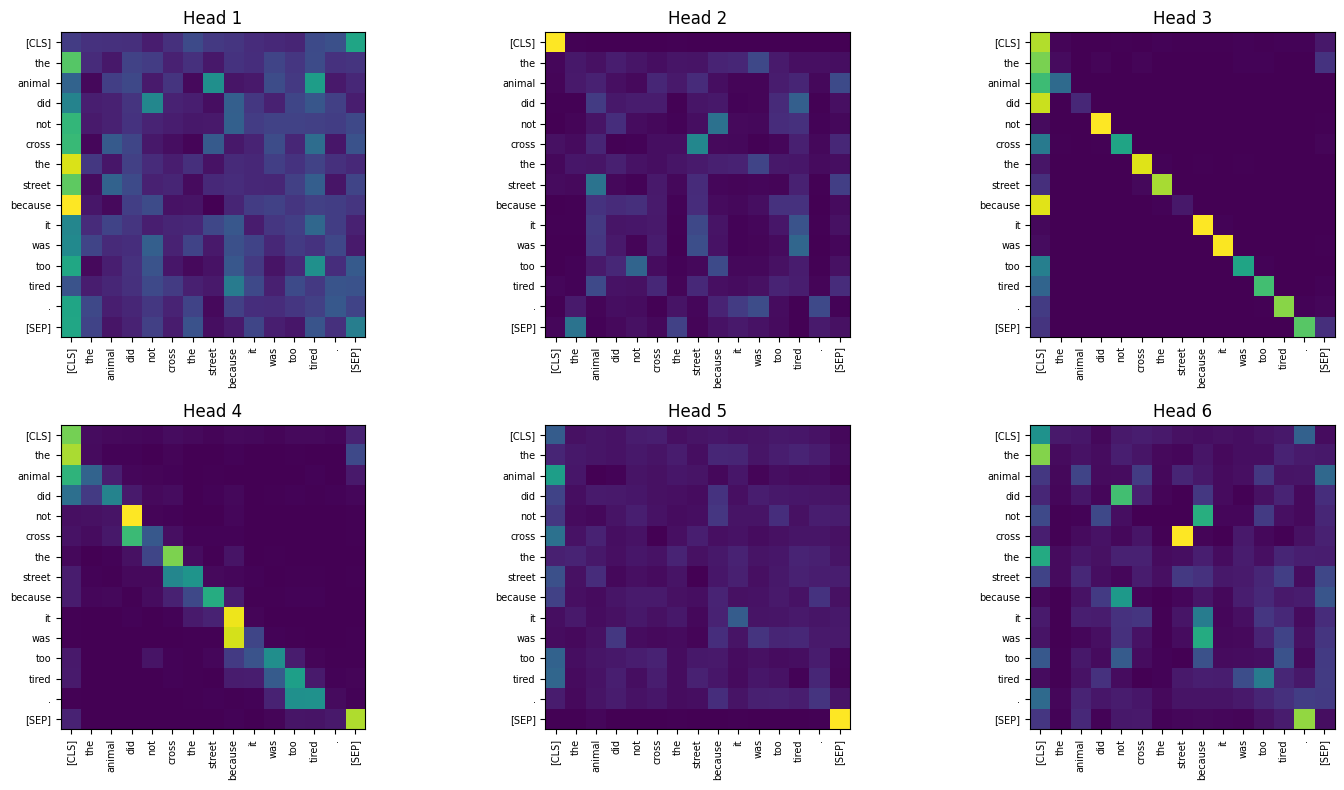

In [46]:
import torch
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, AutoModel

name = "distilbert/distilbert-base-uncased-finetuned-sst-2-english"
tokenizer = AutoTokenizer.from_pretrained(name)
model = AutoModel.from_pretrained(name, attn_implementation="eager")
model.eval()

text = "The animal did not cross the street because it was too tired."
inputs = tokenizer(text, return_tensors="pt")

with torch.no_grad():
    outputs = model(**inputs, output_attentions=True)

tokens = tokenizer.convert_ids_to_tokens(inputs["input_ids"][0])
attn = outputs.attentions[0][0]  # (heads, tokens, tokens)

print("Attention shape:", outputs.attentions[0].shape)
print("Tokens:", tokens)

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for i, ax in enumerate(axes.flat):
    ax.imshow(attn[i].numpy(), cmap="viridis")
    ax.set_title(f"Head {i+1}")
    ax.set_xticks(range(len(tokens)))
    ax.set_yticks(range(len(tokens)))
    ax.set_xticklabels(tokens, rotation=90, fontsize=7)
    ax.set_yticklabels(tokens, fontsize=7)

plt.tight_layout()
plt.show()

Layer 0:
Head entropies: [2.494 2.065 0.553 1.251 2.313 2.137 2.245 1.616 1.795 1.244 0.699 1.817]
Average entropy: 1.686


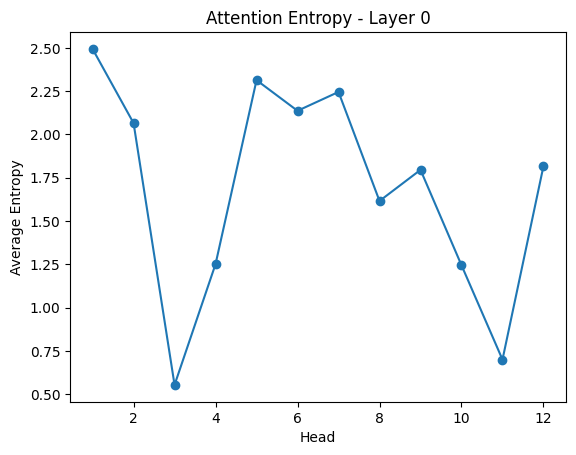

Layer -1:
Head entropies: [2.035 1.862 2.267 1.892 1.928 1.979 1.993 1.762 1.948 2.291 2.065 2.092]
Average entropy: 2.01


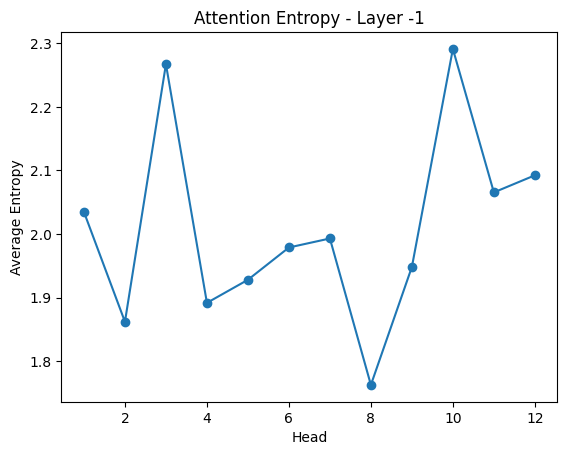

In [47]:
import numpy as np

for layer_id in [0, -1]:
    A = outputs.attentions[layer_id][0].numpy()
    entropy = -(A * np.log(A + 1e-12)).sum(axis=-1).mean(axis=-1)

    print(f"Layer {layer_id}:")
    print("Head entropies:", entropy.round(3))
    print("Average entropy:", entropy.mean().round(3))

    plt.plot(range(1, len(entropy)+1), entropy, marker="o")
    plt.title(f"Attention Entropy - Layer {layer_id}")
    plt.xlabel("Head")
    plt.ylabel("Average Entropy")
    plt.show()

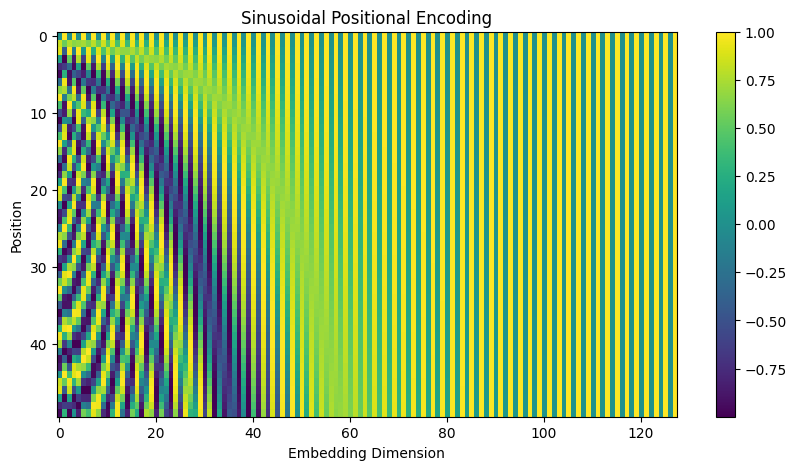

In [48]:
import numpy as np
import matplotlib.pyplot as plt

def positional_encoding(seq_len, d_model):
    pos = np.arange(seq_len)[:, None]
    i = np.arange(d_model)[None, :]
    angle = pos / (10000 ** (2 * (i // 2) / d_model))
    PE = np.where(i % 2 == 0, np.sin(angle), np.cos(angle))
    return PE

PE = positional_encoding(50, 128)

plt.figure(figsize=(10, 5))
plt.imshow(PE, aspect="auto", cmap="viridis")
plt.xlabel("Embedding Dimension")
plt.ylabel("Position")
plt.title("Sinusoidal Positional Encoding")
plt.colorbar()
plt.show()

In [49]:
np.random.seed(42)

word = np.random.randn(128)
PE = positional_encoding(10, 128)

v1 = word + PE[3]
v2 = word + PE[7]

similarity = np.dot(v1, v2) / (np.linalg.norm(v1) * np.linalg.norm(v2))

print("Cosine similarity without PE: 1.0")
print("Cosine similarity with PE:", round(similarity, 4))

Cosine similarity without PE: 1.0
Cosine similarity with PE: 0.9109


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert/distilbert-base-uncased-finetuned-sst-2-english
Key                   | Status     |  | 
----------------------+------------+--+-
classifier.bias       | UNEXPECTED |  | 
pre_classifier.weight | UNEXPECTED |  | 
pre_classifier.bias   | UNEXPECTED |  | 
classifier.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Positional embedding shape: (512, 768)


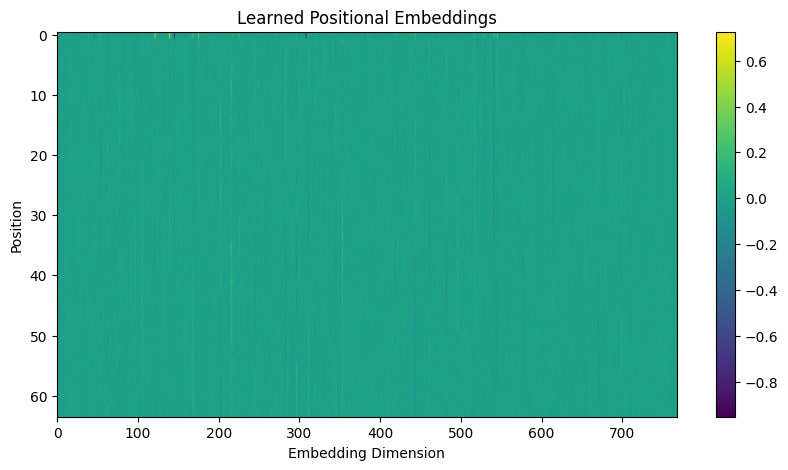


**Note:** DistilBERT uses learned absolute positional embeddings.
Other models, such as T5, use relative position biases.


In [50]:
import torch
import matplotlib.pyplot as plt
from transformers import AutoModel

model = AutoModel.from_pretrained(name)
PE = model.embeddings.position_embeddings.weight.detach().numpy()

print("Positional embedding shape:", PE.shape)

plt.figure(figsize=(10, 5))
plt.imshow(PE[:64], aspect="auto", cmap="viridis")
plt.xlabel("Embedding Dimension")
plt.ylabel("Position")
plt.title("Learned Positional Embeddings")
plt.colorbar()
plt.show()

display(Markdown("""
**Note:** DistilBERT uses learned absolute positional embeddings.
Other models, such as T5, use relative position biases.
"""))

In [51]:
import numpy as np

np.random.seed(42)
X = np.random.randn(4, 8)
gamma, beta = np.ones(8), np.zeros(8)

def layer_norm(X, gamma, beta, eps=1e-5):
    mean = X.mean(axis=-1, keepdims=True)
    var = X.var(axis=-1, keepdims=True)
    return gamma * (X - mean) / np.sqrt(var + eps) + beta

Y = layer_norm(X, gamma, beta)

print("Output:\n", Y.round(3))
print("Row means:", Y.mean(axis=1).round(4))
print("Row std:", Y.std(axis=1).round(4))

Output:
 [[-0.079 -1.004  0.141  1.416 -1.144 -1.144  1.498  0.315]
 [ 0.166  1.439  0.174  0.171  1.061 -1.649 -1.412  0.05 ]
 [-0.666  0.758 -0.554 -1.095  1.993  0.178  0.493 -1.108]
 [-0.509  0.252 -1.214  0.56  -0.574 -0.215 -0.576  2.276]]
Row means: [-0.  0. -0.  0.]
Row std: [1. 1. 1. 1.]


In [52]:
import torch
import torch.nn as nn
from IPython.display import display, Markdown

X = torch.randn(4, 8)

ln = nn.LayerNorm(8)
bn = nn.BatchNorm1d(8)

ln_out = ln(X)
bn_out = bn(X)

print("Input:\n", X)
print("LayerNorm row means:", ln_out.mean(1))
print("LayerNorm row std:", ln_out.std(1, unbiased=False))
print("BatchNorm column means:", bn_out.mean(0))
print("BatchNorm column std:", bn_out.std(0, unbiased=False))

model = AutoModel.from_pretrained(name)
ln_weights = model.embeddings.LayerNorm

print("LayerNorm gamma:", ln_weights.weight[:10].detach())
print("LayerNorm beta:", ln_weights.bias[:10].detach())

display(Markdown("""
### LayerNorm vs BatchNorm
- LayerNorm normalizes features for each token independently.
- BatchNorm normalizes each feature across the batch.
- LayerNorm is more suitable for Transformers because its statistics do not depend on batch size.
- Padding and variable-length sequences can complicate BatchNorm.
- Gamma is the learnable scale; beta is the learnable shift.
"""))

Input:
 tensor([[-0.0214,  1.8928,  0.1437,  0.4597,  1.2354, -1.5374,  0.3793,  0.7484],
        [-1.8102, -0.3646,  0.9724,  1.1315, -1.1963,  2.1659,  1.0323,  0.0753],
        [-1.6048,  0.7375,  0.2948, -1.5334, -1.1803,  0.1168,  0.1987, -2.3179],
        [-0.5720, -0.1491, -0.5592, -1.5062,  0.9247, -0.4616, -0.4628, -1.3441]])
LayerNorm row means: tensor([2.2352e-08, 7.4506e-09, 0.0000e+00, 1.4901e-08],
       grad_fn=<MeanBackward1>)
LayerNorm row std: tensor([1.0000, 1.0000, 1.0000, 1.0000], grad_fn=<StdBackward0>)
BatchNorm column means: tensor([ 7.4506e-08,  0.0000e+00,  2.9802e-08, -4.4703e-08,  0.0000e+00,
         1.4901e-08, -2.9802e-08, -1.4901e-08], grad_fn=<MeanBackward1>)
BatchNorm column std: tensor([1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000],
       grad_fn=<StdBackward0>)


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert/distilbert-base-uncased-finetuned-sst-2-english
Key                   | Status     |  | 
----------------------+------------+--+-
classifier.bias       | UNEXPECTED |  | 
pre_classifier.weight | UNEXPECTED |  | 
pre_classifier.bias   | UNEXPECTED |  | 
classifier.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


LayerNorm gamma: tensor([0.8445, 0.7974, 0.7331, 0.7594, 0.8013, 0.7861, 0.8170, 0.8177, 0.8369,
        0.7073])
LayerNorm beta: tensor([ 0.0443,  0.0614,  0.0692,  0.0874, -0.0584, -0.1601,  0.1443, -0.0606,
        -0.0279,  0.1222])



### LayerNorm vs BatchNorm
- LayerNorm normalizes features for each token independently.
- BatchNorm normalizes each feature across the batch.
- LayerNorm is more suitable for Transformers because its statistics do not depend on batch size.
- Padding and variable-length sequences can complicate BatchNorm.
- Gamma is the learnable scale; beta is the learnable shift.


# TASK : 4

In [53]:
from IPython.display import display, Markdown

display(Markdown("""
### Transformer Encoder
Input Embeddings + Positional Embeddings
              ↓
Multi-Head Self-Attention
              ↓
Residual Connection + LayerNorm
              ↓
Feed-Forward Network (Linear → GELU → Linear)
              ↓
Residual Connection + LayerNorm
              ↓
Output Representations

DistilBERT has 6 encoder layers and 12 attention heads.
Each token can attend to tokens on both sides (bidirectional).
"""))


### Transformer Encoder
Input Embeddings + Positional Embeddings
              ↓
Multi-Head Self-Attention
              ↓
Residual Connection + LayerNorm
              ↓
Feed-Forward Network (Linear → GELU → Linear)
              ↓
Residual Connection + LayerNorm
              ↓
Output Representations

DistilBERT has 6 encoder layers and 12 attention heads.
Each token can attend to tokens on both sides (bidirectional).


In [54]:
from transformers import AutoModel

name = "distilbert/distilbert-base-uncased-finetuned-sst-2-english"
model = AutoModel.from_pretrained(name)

for n, p in model.named_parameters():
    if any(x in n for x in ["embeddings", "attention", "ffn", "LayerNorm"]):
        print(n, tuple(p.shape))

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert/distilbert-base-uncased-finetuned-sst-2-english
Key                   | Status     |  | 
----------------------+------------+--+-
classifier.bias       | UNEXPECTED |  | 
pre_classifier.weight | UNEXPECTED |  | 
pre_classifier.bias   | UNEXPECTED |  | 
classifier.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


embeddings.word_embeddings.weight (30522, 768)
embeddings.position_embeddings.weight (512, 768)
embeddings.LayerNorm.weight (768,)
embeddings.LayerNorm.bias (768,)
transformer.layer.0.attention.q_lin.weight (768, 768)
transformer.layer.0.attention.q_lin.bias (768,)
transformer.layer.0.attention.k_lin.weight (768, 768)
transformer.layer.0.attention.k_lin.bias (768,)
transformer.layer.0.attention.v_lin.weight (768, 768)
transformer.layer.0.attention.v_lin.bias (768,)
transformer.layer.0.attention.out_lin.weight (768, 768)
transformer.layer.0.attention.out_lin.bias (768,)
transformer.layer.0.ffn.lin1.weight (3072, 768)
transformer.layer.0.ffn.lin1.bias (3072,)
transformer.layer.0.ffn.lin2.weight (768, 3072)
transformer.layer.0.ffn.lin2.bias (768,)
transformer.layer.1.attention.q_lin.weight (768, 768)
transformer.layer.1.attention.q_lin.bias (768,)
transformer.layer.1.attention.k_lin.weight (768, 768)
transformer.layer.1.attention.k_lin.bias (768,)
transformer.layer.1.attention.v_lin.weigh

embeddings 23835648
layer 42527232


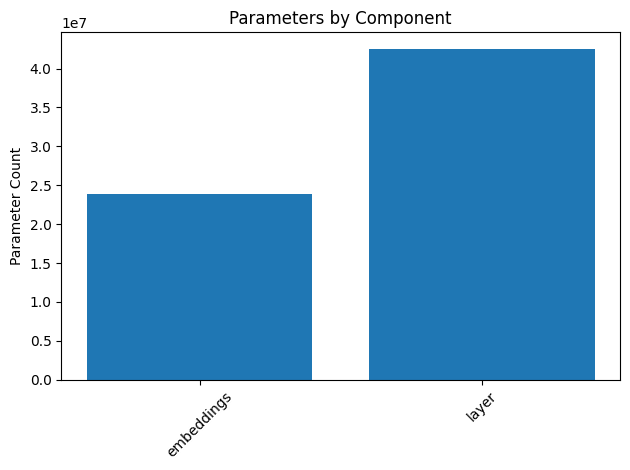

In [55]:
from collections import defaultdict
import matplotlib.pyplot as plt

groups = defaultdict(int)

for n, p in model.named_parameters():
    key = n.split(".")[1] if n.startswith("transformer.") else n.split(".")[0]
    groups[key] += p.numel()

for k, v in groups.items():
    print(k, v)

plt.bar(groups.keys(), groups.values())
plt.xticks(rotation=45)
plt.ylabel("Parameter Count")
plt.title("Parameters by Component")
plt.tight_layout()
plt.show()

In [56]:
from transformers import pipeline

fill = pipeline("fill-mask", model="distilbert/distilbert-base-uncased")
texts = [
    "The capital of France is [MASK].",
    "I drink [MASK] every morning.",
    "The sky is [MASK] today."
]

for text in texts:
    print("\n", text)
    for r in fill(text, top_k=3):
        print(r["token_str"], round(r["score"], 4))

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]


 The capital of France is [MASK].
marseille 0.1427
nantes 0.0902
toulouse 0.0881

 I drink [MASK] every morning.
coffee 0.2506
tea 0.0673
water 0.0591

 The sky is [MASK] today.
visible 0.1035
blue 0.0936
clear 0.09


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert/distilbert-base-uncased-finetuned-sst-2-english
Key                   | Status     |  | 
----------------------+------------+--+-
classifier.bias       | UNEXPECTED |  | 
pre_classifier.weight | UNEXPECTED |  | 
pre_classifier.bias   | UNEXPECTED |  | 
classifier.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


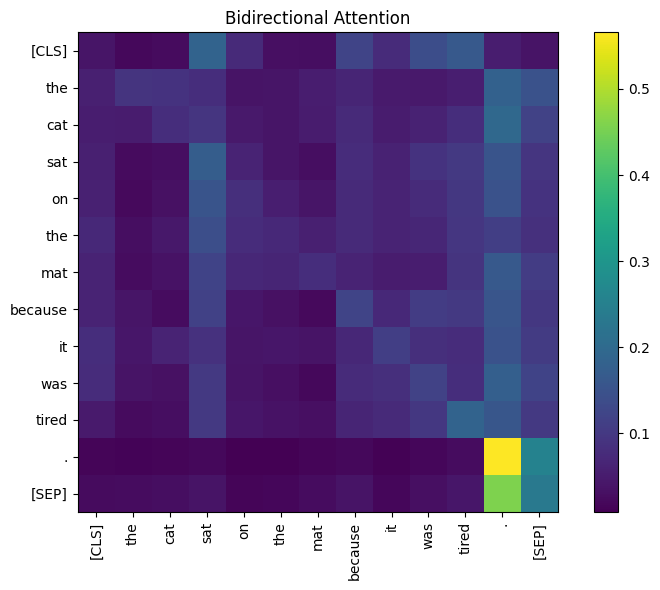

In [57]:
import torch
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, AutoModel

name = "distilbert/distilbert-base-uncased-finetuned-sst-2-english"

tokenizer = AutoTokenizer.from_pretrained(name)
model = AutoModel.from_pretrained(
    name, attn_implementation="eager"
)
model.eval()

text = "The cat sat on the mat because it was tired."
inputs = tokenizer(text, return_tensors="pt")

with torch.no_grad():
    out = model(**inputs, output_attentions=True)

tokens = tokenizer.convert_ids_to_tokens(inputs["input_ids"][0])
A = out.attentions[-1][0].mean(0).numpy()

plt.figure(figsize=(8, 6))
plt.imshow(A, cmap="viridis")
plt.xticks(range(len(tokens)), tokens, rotation=90)
plt.yticks(range(len(tokens)), tokens)
plt.title("Bidirectional Attention")
plt.colorbar()
plt.tight_layout()
plt.show()
plt.show()

In [58]:
import numpy as np

np.random.seed(42)
X = np.random.randn(6, 8)
Q, K, V = X, X, X

scores = Q @ K.T / np.sqrt(8)
mask = np.triu(np.ones((6, 6)), k=1)
scores[mask == 1] = -np.inf

weights = np.exp(scores - np.max(scores, axis=1, keepdims=True))
weights /= weights.sum(axis=1, keepdims=True)

print("Causal Attention:\n", weights.round(3))
print("Upper triangle:", weights[np.triu_indices(6, k=1)])

Causal Attention:
 [[1.    0.    0.    0.    0.    0.   ]
 [0.014 0.986 0.    0.    0.    0.   ]
 [0.009 0.145 0.845 0.    0.    0.   ]
 [0.095 0.129 0.038 0.738 0.    0.   ]
 [0.011 0.213 0.042 0.03  0.703 0.   ]
 [0.088 0.115 0.021 0.218 0.155 0.404]]
Upper triangle: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


In [59]:
from transformers import AutoTokenizer, AutoModelForCausalLM
import torch

name_gpt = "openai-community/gpt2"
tok = AutoTokenizer.from_pretrained(name_gpt)
gpt = AutoModelForCausalLM.from_pretrained(
    name_gpt, attn_implementation="eager"
)
gpt.eval()

x = tok("Transformers process text", return_tensors="pt")

with torch.no_grad():
    out = gpt(**x, output_attentions=True)

A = out.attentions[-1][0, 0]
print("Attention shape:", A.shape)
print("Maximum attention above diagonal:",
      torch.triu(A, diagonal=1).max().item())

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Attention shape: torch.Size([4, 4])
Maximum attention above diagonal: 0.0


In [60]:
from transformers import AutoTokenizer, AutoModel
import torch

name = "distilbert/distilbert-base-uncased-finetuned-sst-2-english"
tokenizer = AutoTokenizer.from_pretrained(name)
model = AutoModel.from_pretrained(name, attn_implementation="eager")
model.eval()

texts = ["I love AI.", "Transformers are powerful language models."]
inputs = tokenizer(texts, padding=True, return_tensors="pt")

with torch.no_grad():
    out = model(**inputs, output_attentions=True)


A = out.attentions[0]
print("Attention shape:", A.shape)
print("Padding mask:\n", inputs["attention_mask"])
print("Attention to padding tokens:", A[1, :, :, 5:].abs().max().item())

display(Markdown("""
| Feature | Padding Mask | Causal Mask |
|---|---|---|
| Purpose | Ignore padding tokens | Prevent looking at future tokens |
| Shape | Batch × sequence | Sequence × sequence |
| Used in | BERT, DistilBERT | GPT |
| Attention | Masks padding keys | Masks future positions |
"""))

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert/distilbert-base-uncased-finetuned-sst-2-english
Key                   | Status     |  | 
----------------------+------------+--+-
classifier.bias       | UNEXPECTED |  | 
pre_classifier.weight | UNEXPECTED |  | 
pre_classifier.bias   | UNEXPECTED |  | 
classifier.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Attention shape: torch.Size([2, 12, 8, 8])
Padding mask:
 tensor([[1, 1, 1, 1, 1, 1, 0, 0],
        [1, 1, 1, 1, 1, 1, 1, 1]])
Attention to padding tokens: 0.9784616231918335



| Feature | Padding Mask | Causal Mask |
|---|---|---|
| Purpose | Ignore padding tokens | Prevent looking at future tokens |
| Shape | Batch × sequence | Sequence × sequence |
| Used in | BERT, DistilBERT | GPT |
| Attention | Masks padding keys | Masks future positions |


# TASK : 5

In [61]:
from IPython.display import display, Markdown

display(Markdown("""
### Transformer Decoder
Input Tokens → Embeddings + Positional Encoding
→ Masked Multi-Head Self-Attention
→ Add & LayerNorm
→ Cross-Attention (in encoder-decoder models)
→ Add & LayerNorm
→ Feed-Forward Network
→ Add & LayerNorm
→ Linear Layer → Softmax → Next Token

GPT-2: Decoder-only; T5: Encoder-decoder; DistilBERT: Encoder-only.
"""))


### Transformer Decoder
Input Tokens → Embeddings + Positional Encoding
→ Masked Multi-Head Self-Attention
→ Add & LayerNorm
→ Cross-Attention (in encoder-decoder models)
→ Add & LayerNorm
→ Feed-Forward Network
→ Add & LayerNorm
→ Linear Layer → Softmax → Next Token

GPT-2: Decoder-only; T5: Encoder-decoder; DistilBERT: Encoder-only.


In [62]:
display(Markdown("""
### Cross-Attention
- Query (Q) comes from the decoder.
- Key (K) and Value (V) come from the encoder.
- It allows the decoder to focus on relevant input words.
- Example: During translation, the decoder attends to source words
  while generating each target word.
"""))


### Cross-Attention
- Query (Q) comes from the decoder.
- Key (K) and Value (V) come from the encoder.
- It allows the decoder to focus on relevant input words.
- Example: During translation, the decoder attends to source words
  while generating each target word.


In [64]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

model_name = "google-t5/t5-small"

tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSeq2SeqLM.from_pretrained(model_name)
model.eval()

texts = [
    "translate English to French: Hello, how are you?",
    "translate English to French: I love learning artificial intelligence.",
    "translate English to French: The weather is very nice today."
]

for text in texts:
    inputs = tokenizer(text, return_tensors="pt", truncation=True)

    outputs = model.generate(**inputs, max_new_tokens=60)

    result = tokenizer.decode(outputs[0], skip_special_tokens=True)
    print(text, "->", result)

config.json:   0%|          | 0.00/1.21k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.32k [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/792k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.39M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  242MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

translate English to French: Hello, how are you? -> Bonjour, comment êtes-vous?
translate English to French: I love learning artificial intelligence. -> Je m'aime apprendre l'intelligence artificielle.
translate English to French: The weather is very nice today. -> Le temps est très agréable aujourd'hui.


tokenizer_config.json:   0%|          | 0.00/2.32k [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/792k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.39M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

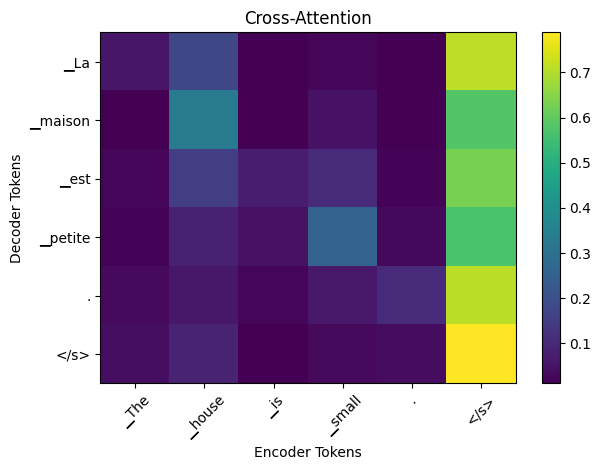

In [65]:
import torch
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

name = "t5-small"
tok = AutoTokenizer.from_pretrained(name)
model = AutoModelForSeq2SeqLM.from_pretrained(
    name, attn_implementation="eager"
)
model.eval()

src = tok("The house is small.", return_tensors="pt")
tgt = tok("La maison est petite.", return_tensors="pt")

with torch.no_grad():
    out = model(**src, labels=tgt["input_ids"],
                output_attentions=True)

A = out.cross_attentions[-1][0].mean(0).numpy()
src_tokens = tok.convert_ids_to_tokens(src["input_ids"][0])
tgt_tokens = tok.convert_ids_to_tokens(tgt["input_ids"][0])

plt.imshow(A, cmap="viridis", aspect="auto")
plt.xticks(range(len(src_tokens)), src_tokens, rotation=45)
plt.yticks(range(len(tgt_tokens)), tgt_tokens)
plt.xlabel("Encoder Tokens")
plt.ylabel("Decoder Tokens")
plt.title("Cross-Attention")
plt.colorbar()
plt.tight_layout()
plt.show()

In [66]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

name = "openai-community/gpt2"
tok = AutoTokenizer.from_pretrained(name)
model = AutoModelForCausalLM.from_pretrained(name)
model.eval()

prompt = "Artificial intelligence will"
ids = tok(prompt, return_tensors="pt").input_ids

with torch.no_grad():
    for _ in range(20):
        logits = model(ids).logits[:, -1, :]
        next_id = logits.argmax(dim=-1, keepdim=True)
        ids = torch.cat([ids, next_id], dim=1)

print(tok.decode(ids[0], skip_special_tokens=True))

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Artificial intelligence will be able to do things like search for and find people, and to do things like find out who


In [67]:
prompt = "Artificial intelligence will"
inputs = tok(prompt, return_tensors="pt")

strategies = {
    "Greedy": dict(do_sample=False),
    "Sampling": dict(do_sample=True, temperature=0.7),
    "Top-k": dict(do_sample=True, top_k=50, temperature=0.8),
    "Top-p": dict(do_sample=True, top_p=0.9, temperature=0.8),
    "Beam search": dict(do_sample=False, num_beams=3)
}

for name, params in strategies.items():
    torch.manual_seed(42)
    with torch.no_grad():
        ids = model.generate(**inputs, max_new_tokens=40, **params)
    print(name, ":", tok.decode(ids[0], skip_special_tokens=True))

Greedy : Artificial intelligence will be able to do things like search for and find people, and to do things like find out who's in the right place at the right time.

"We're going to be able to
Sampling : Artificial intelligence will be used to create artificial intelligence in the future, but it is not yet a fully mature technology. For example, there is no commercial use of artificial intelligence in the United States. The United States is
Top-k : Artificial intelligence will be used more to create new algorithms than more traditional tools, experts say.

It's also being used for "programmatic analysis," which makes it easier to keep track of what is happening in
Top-p : Artificial intelligence will be used to create artificial intelligence in ways that will allow for the creation of a new type of human being. The technology is called artificial intelligence (AI) and its use will be limited to the areas
Beam search : Artificial intelligence will be the next big thing.

"I think it's

In [68]:
import time

inputs = tok("Artificial intelligence is", return_tensors="pt")

for use_cache in [True, False]:
    start = time.time()
    with torch.no_grad():
        model.generate(**inputs, max_new_tokens=100,
                       use_cache=use_cache, do_sample=False)
    print(f"Cache={use_cache}: {time.time()-start:.2f} seconds")

Cache=True: 6.18 seconds
Cache=False: 30.43 seconds


In [69]:
display(Markdown("""
| Model | Architecture | Attention | Typical Tasks |
|---|---|---|---|
| DistilBERT | Encoder-only | Bidirectional | Classification, sentiment |
| GPT-2 | Decoder-only | Causal | Text generation |
| T5-small | Encoder-decoder | Self + Cross | Translation, summarization |

- DistilBERT learns from both left and right context.
- GPT-2 predicts the next token using previous tokens.
- T5 encodes input and generates output using cross-attention.
"""))


| Model | Architecture | Attention | Typical Tasks |
|---|---|---|---|
| DistilBERT | Encoder-only | Bidirectional | Classification, sentiment |
| GPT-2 | Decoder-only | Causal | Text generation |
| T5-small | Encoder-decoder | Self + Cross | Translation, summarization |

- DistilBERT learns from both left and right context.
- GPT-2 predicts the next token using previous tokens.
- T5 encodes input and generates output using cross-attention.


# TASK : 6

In [71]:
!pip install -q transformers datasets torch pandas matplotlib scikit-learn

In [75]:
texts = list(data["text"])
y = list(data["label"])

print(type(texts), type(texts[0]))

<class 'list'> <class 'str'>


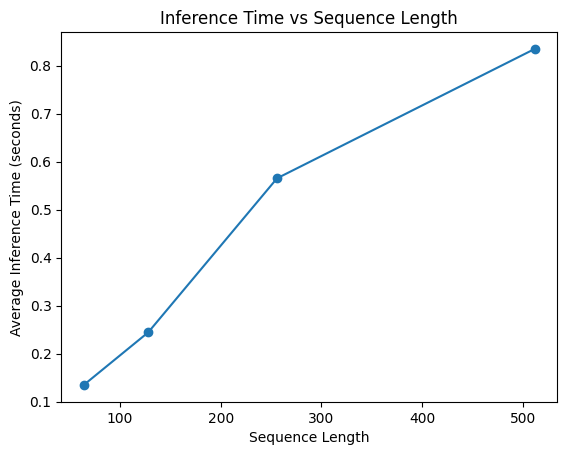

In [80]:
times = []

for length in [64, 128, 256, 512]:
    batch = clf.tokenizer(
        ["This is a sample review. " * 150],
        return_tensors="pt", truncation=True,
        max_length=length, padding="max_length"
    )
    batch = {k: v.to(clf.model.device) for k, v in batch.items()}

    with torch.no_grad():
        clf.model(**batch)  # warm-up
        start = time.time()
        for _ in range(10):
            clf.model(**batch)
        elapsed = (time.time() - start) / 10

    times.append(elapsed)

plt.plot([64, 128, 256, 512], times, marker="o")
plt.xlabel("Sequence Length")
plt.ylabel("Average Inference Time (seconds)")
plt.title("Inference Time vs Sequence Length")
plt.show()

In [81]:
from transformers import AutoTokenizer, AutoModelForCausalLM

name = "openai-community/gpt2"
tok = AutoTokenizer.from_pretrained(name)
gpt = AutoModelForCausalLM.from_pretrained(name)
gpt.eval()
tok.pad_token = tok.eos_token

prompts = [
    "The capital of Australia is",
    "The author of Pride and Prejudice is",
    "The inventor of the telephone was"
]

for prompt in prompts:
    x = tok(prompt, return_tensors="pt")
    with torch.no_grad():
        out = gpt.generate(**x, max_new_tokens=30, do_sample=False,
                           pad_token_id=tok.eos_token_id)
    print(tok.decode(out[0], skip_special_tokens=True), "\n")

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

The capital of Australia is the world's largest producer of coal, and the country's largest coal-fired power station.

The coal industry is also the world's largest 

The author of Pride and Prejudice is a former member of the National Security Council and a former senior adviser to President Barack Obama.

The author of the book is a former member of 

The inventor of the telephone was a man named John D. Rockefeller. He was a man who had been a member of the Rockefeller family for many years. He was a man who 



In [83]:
from IPython.display import display, Markdown

display(Markdown("""
### Reflection
- Self-attention helps Transformers understand relationships between words.
- Truncation limits how much text the model can process.
- Longer sequences generally require more computation.
- GPT-2 can generate incorrect information confidently.
- Transformers are useful for sentiment analysis, summarization, and translation.
- Applications should verify important information instead of trusting every output.
"""))


### Reflection
- Self-attention helps Transformers understand relationships between words.
- Truncation limits how much text the model can process.
- Longer sequences generally require more computation.
- GPT-2 can generate incorrect information confidently.
- Transformers are useful for sentiment analysis, summarization, and translation.
- Applications should verify important information instead of trusting every output.
